In [1]:
'''
                    STEP 4
              CNN/MIL aggregation
                     │
                     │ 64 features
                     ▼
              ┌──────────────┐
              │ record_id    │
              │ cnn_mean_*   │
              │ cnn_max_*    │
              │ cnn_std_*    │
              │ cnn_latest_* │
              └──────┬───────┘
                     │
                     │ merge on record_id
                     ▼
TABULAR_CSV ──────────────────────────┐
│ record_id                           │
│ FHR handcrafted features            │
│ UC handcrafted features             │
│ clinical features                   │
│ y_class                             │
└─────────────────────────────────────┘
                     │
                     ▼
             FINAL FEATURE TABLE
                     │
          ┌──────────┴──────────┐
          │                     │
          ▼                     ▼
       X features            y_class
          │                     │
          └──────────┬──────────┘
                     ▼
                  LightGBM

  '''

'\n                    STEP 4\n              CNN/MIL aggregation\n                     │\n                     │ 64 features\n                     ▼\n              ┌──────────────┐\n              │ record_id    │\n              │ cnn_mean_*   │\n              │ cnn_max_*    │\n              │ cnn_std_*    │\n              │ cnn_latest_* │\n              └──────┬───────┘\n                     │\n                     │ merge on record_id\n                     ▼\nTABULAR_CSV ──────────────────────────┐\n│ record_id                           │\n│ FHR handcrafted features            │\n│ UC handcrafted features             │\n│ clinical features                   │\n│ y_class                             │\n└─────────────────────────────────────┘\n                     │\n                     ▼\n             FINAL FEATURE TABLE\n                     │\n          ┌──────────┴──────────┐\n          │                     │\n          ▼                     ▼\n       X features            y_class\

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# ==============================================================================
# STEP 2: LOAD PREPROCESSED MIL BAGS
# ==============================================================================

import pickle


TABULAR_CSV = "/content/drive/MyDrive/Colab Notebooks/Fetal_project/cnn_tabular_features_final_no_missingness.csv" #cnn_tabular_features_final_PH715.csv"

BAGS_PATH = (
    "/content/drive/My Drive/Colab Notebooks/Fetal_project/"
    "ctu_4channel_mil_bags.pkl"
)

with open(BAGS_PATH, "rb") as f:
    mil_bags = pickle.load(f)

print(f"[MIL BAGS] Loaded {len(mil_bags)} records.")

[MIL BAGS] Loaded 546 records.


In [4]:
# ==============================================================================
# STEP 3: PREPARE MIL BAGS FOR CNN + MIL + PH TRAINING
# ==============================================================================

if 'mil_bags' not in globals():
    raise NameError(
        "`mil_bags` not found. Please run Step 2 first."
    )

print(
    f"[INIT] Loaded `mil_bags` containing valid chunks "
    f"for {len(mil_bags)} records."
)

first_rid = next(iter(mil_bags))

print(
    f"[CHECK] Example record ID: {first_rid}"
)

print(
    f"[CHECK] Bag shape: {mil_bags[first_rid].shape}"
)

print(
    "[INFO] These raw bags will be passed to the trainable CNN."
)

print(
    "[INFO] CNN embeddings will be learned during CNN/MIL/PH training."
)

[INIT] Loaded `mil_bags` containing valid chunks for 546 records.
[CHECK] Example record ID: 1001
[CHECK] Bag shape: (14, 4, 3600)
[INFO] These raw bags will be passed to the trainable CNN.
[INFO] CNN embeddings will be learned during CNN/MIL/PH training.


In [ ]:
# ==============================================================================
# STEP 4: CNN ENCODER TRAINING — CHUNK-LEVEL REPRESENTATION LEARNING
# ==============================================================================
#
# Objective:
#   Learn Conv1 -> Conv2 -> Conv3 representations from the CTG chunks.
#
# IMPORTANT:
#   - NO statistical aggregation yet.
#   - NO mean/max/std pooling yet.
#   - NO LightGBM yet.
#   - The CNN learns its convolutional weights here.
#
# Output:
#   cnn_model
#   record_embeddings
#
# `record_embeddings[rid]` will contain the learned representation
# for every valid chunk belonging to that patient.
# ==============================================================================

import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    BatchNormalization,
    ReLU,
    MaxPooling1D,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping


# ==============================================================================
# 1. VERIFY INPUTS
# ==============================================================================

if "mil_bags" not in globals():
    raise NameError(
        "`mil_bags` not found. Please run Step 2 first."
    )

print("=" * 80)
print("STEP 4: CNN REPRESENTATION LEARNING")
print("=" * 80)

print(
    f"[INPUT] Records available in MIL bags: "
    f"{len(mil_bags)}"
)


# ==============================================================================
# 2. LOAD PATIENT-LEVEL TARGETS
# ==============================================================================



tabular_df = pd.read_csv(TABULAR_CSV)

if "record_id" not in tabular_df.columns:
    raise ValueError(
        "`record_id` not found in tabular dataset."
    )

if "y_class" not in tabular_df.columns:
    raise ValueError(
        "`y_class` not found in tabular dataset."
    )

target_df = (
    tabular_df[
        ["record_id", "y_class"]
    ]
    .drop_duplicates("record_id")
    .copy()
)

target_df["record_id"] = target_df["record_id"].astype(int)

print(
    f"[TARGET] Patient-level records: "
    f"{len(target_df)}"
)


# ==============================================================================
# 3. COLLECT CHUNKS + PATIENT LABELS
# ==============================================================================

X_chunks = []
y_chunks = []
chunk_record_ids = []

for rid, bag in mil_bags.items():

    rid = int(rid)

    match = target_df[
        target_df["record_id"] == rid
    ]

    if len(match) == 0:
        continue

    y_value = match["y_class"].iloc[0]

    if pd.isna(y_value):
        continue

    # --------------------------------------------------------------
    # Expected bag shape:
    #
    #     (n_chunks, channels, time)
    # --------------------------------------------------------------

    bag = np.asarray(bag)

    if bag.ndim != 3:
        raise ValueError(
            f"Unexpected bag shape for record {rid}: "
            f"{bag.shape}. Expected "
            f"(n_chunks, channels, time)."
        )

    for chunk in bag:

        X_chunks.append(chunk)
        y_chunks.append(int(y_value))
        chunk_record_ids.append(rid)


X_chunks = np.asarray(X_chunks, dtype=np.float32)
y_chunks = np.asarray(y_chunks, dtype=np.int32)

print()
print("[CHUNKS]")
print(f"  Shape: {X_chunks.shape}")
print(f"  Number of chunks: {len(X_chunks)}")
print(f"  Number of channels: {X_chunks.shape[1]}")
print(f"  Time points/chunk: {X_chunks.shape[2]}")


# ==============================================================================
# 4. TRANSPOSE FOR KERAS Conv1D
# ==============================================================================
#
# Keras Conv1D expects:
#
#     (samples, time, channels)
#
# whereas the MIL bags are assumed to be:
#
#     (chunks, channels, time)
#
# Therefore:
#
#     (N, C, T) -> (N, T, C)
# ==============================================================================

X_chunks = np.transpose(
    X_chunks,
    (0, 2, 1)
)

print(
    f"[CNN INPUT] Final chunk tensor: "
    f"{X_chunks.shape}"
)


# ==============================================================================
# 5. BUILD CNN ENCODER
# ==============================================================================

N_CHANNELS = X_chunks.shape[-1]
N_TIMESTEPS = X_chunks.shape[1]

EMBEDDING_DIM = 16

inputs = Input(
    shape=(N_TIMESTEPS, N_CHANNELS),
    name="ctg_input"
)

x = Conv1D(
    filters=32,
    kernel_size=7,
    padding="same",
    name="conv1"
)(inputs)

x = BatchNormalization()(x)
x = ReLU()(x)
x = MaxPooling1D(
    pool_size=2
)(x)


x = Conv1D(
    filters=64,
    kernel_size=5,
    padding="same",
    name="conv2"
)(x)

x = BatchNormalization()(x)
x = ReLU()(x)
x = MaxPooling1D(
    pool_size=2
)(x)


x = Conv1D(
    filters=128,
    kernel_size=3,
    padding="same",
    name="conv3"
)(x)

x = BatchNormalization()(x)
x = ReLU()(x)


x = GlobalAveragePooling1D()(x)

x = Dense(
    32,
    activation="relu",
    name="dense_representation"
)(x)

x = Dropout(
    0.30
)(x)

outputs = Dense(
    1,
    activation="sigmoid",
    name="prediction"
)(x)


cnn_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="CTG_CNN"
)


# ==============================================================================
# 6. COMPILE CNN
# ==============================================================================

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(name="roc_auc"),
        tf.keras.metrics.AUC(name="pr_auc", curve="PR"),
        tf.keras.metrics.Recall(name="recall")
    ]
)
'''
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(
            name="roc_auc"
        ),
        tf.keras.metrics.AUC(
            name="pr_auc",
            curve="PR"
        ),
        tf.keras.metrics.Recall(
            name="recall"
        )
    ]
)
'''
cnn_model.summary()

# ==============================================================================
# 7. TRAIN CNN — RECORD-LEVEL VALIDATION SPLIT
# ==============================================================================

from sklearn.model_selection import train_test_split


# ------------------------------------------------------------------------------
# 1. Prepare record IDs
# ------------------------------------------------------------------------------

chunk_record_ids = np.asarray(
    chunk_record_ids,
    dtype=np.int64
)

unique_record_ids = np.unique(
    chunk_record_ids
)


# ------------------------------------------------------------------------------
# 2. Get one label per record
# ------------------------------------------------------------------------------

record_labels = []

for rid in unique_record_ids:

    matching_rows = target_df[
        target_df["record_id"] == int(rid)
    ]

    if len(matching_rows) != 1:
        raise ValueError(
            f"Expected exactly one target for record {rid}, "
            f"found {len(matching_rows)}"
        )

    record_labels.append(
        int(matching_rows["y_class"].iloc[0])
    )

record_labels = np.asarray(
    record_labels,
    dtype=np.int32
)


# ------------------------------------------------------------------------------
# 3. Split RECORDS, not chunks
# ------------------------------------------------------------------------------

train_record_ids, val_record_ids = train_test_split(
    unique_record_ids,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=record_labels
)


# ------------------------------------------------------------------------------
# 4. Convert record split into chunk masks
# ------------------------------------------------------------------------------

train_mask = np.isin(
    chunk_record_ids,
    train_record_ids
)

val_mask = np.isin(
    chunk_record_ids,
    val_record_ids
)


X_train = X_chunks[train_mask]
y_train = y_chunks[train_mask]

X_val = X_chunks[val_mask]
y_val = y_chunks[val_mask]


# ------------------------------------------------------------------------------
# 5. Verify no record appears in both sets
# ------------------------------------------------------------------------------

train_record_set = set(
    chunk_record_ids[train_mask]
)

val_record_set = set(
    chunk_record_ids[val_mask]
)

record_overlap = train_record_set.intersection(
    val_record_set
)

if len(record_overlap) > 0:
    raise RuntimeError(
        "Record leakage detected: "
        f"{sorted(record_overlap)}"
    )

if len(
    train_record_set.union(val_record_set)
) != len(unique_record_ids):

    raise RuntimeError(
        "Some records were not assigned to train or validation."
    )


# ------------------------------------------------------------------------------
# 6. Report split
# ------------------------------------------------------------------------------

print()
print("=" * 80)
print("RECORD-LEVEL CNN SPLIT")
print("=" * 80)

print(
    f"Training records:   {len(train_record_set)}"
)

print(
    f"Validation records: {len(val_record_set)}"
)

print(
    f"Training chunks:    {len(X_train)}"
)

print(
    f"Validation chunks:  {len(X_val)}"
)

print(
    f"Record overlap:     {len(record_overlap)}"
)

print(
    f"Training class 0:   {(y_train == 0).sum()}"
)

print(
    f"Training class 1:   {(y_train == 1).sum()}"
)

print(
    f"Validation class 0: {(y_val == 0).sum()}"
)

print(
    f"Validation class 1: {(y_val == 1).sum()}"
)



# ------------------------------------------------------------------------------
# 7. Early stopping
# ------------------------------------------------------------------------------

early_stopping = EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=5,
    restore_best_weights=True
)

# ------------------------------------------------------------------------------
# 8. Unified Sample Weights (Patient-Balance + Class Imbalance)
# ------------------------------------------------------------------------------

# 1. Calculate class weights for imbalance
n0 = np.sum(y_train == 0)
n1 = np.sum(y_train == 1)
class_weights_dict = {0: 1.0, 1: n0 / n1}

# 2. Count chunks per patient record in the training set
train_chunk_records = chunk_record_ids[train_mask]
chunk_counts = pd.Series(train_chunk_records).value_counts()

# 3. Build combined sample weights array for X_train
sample_weights_train = np.zeros(len(y_train), dtype=np.float32)

for i in range(len(y_train)):
    rid = train_chunk_records[i]
    label = y_train[i]

    # Inverse patient chunk count (gives each patient equal total weight)
    patient_weight = 1.0 / chunk_counts[rid]

    # Class imbalance weight
    class_weight = class_weights_dict[label]

    # Combined weight
    sample_weights_train[i] = patient_weight * class_weight

print(f"[SAMPLE WEIGHTS] Created weights for {len(sample_weights_train)} training chunks.")
print(f"[SAMPLE WEIGHTS] Min weight: {sample_weights_train.min():.5f}, Max weight: {sample_weights_train.max():.5f}")


# ------------------------------------------------------------------------------
# 8. Train using explicit record-level validation data
# ------------------------------------------------------------------------------

history = cnn_model.fit(
    X_train,
    y_train,
    validation_data=(
        X_val,
        y_val
    ),
    sample_weight=sample_weights_train, # <--- Replaced class_weight with sample_weight
    epochs=20,
    batch_size=32,
    callbacks=[
        early_stopping
    ],
    verbose=1
)

# ==============================================================================
# 8. CREATE EMBEDDING MODEL
# ==============================================================================
#
# IMPORTANT:
# The CNN has now learned:
#
#     Conv1 weights
#     Conv2 weights
#     Conv3 weights
#
# We now remove the final classification layer and extract the learned
# representation for each chunk.
# ==============================================================================

embedding_model = Model(
    inputs=cnn_model.input,
    outputs=cnn_model.get_layer(
        "dense_representation"
    ).output
)


# ==============================================================================
# 9. EXTRACT CHUNK EMBEDDINGS
# ==============================================================================

chunk_embeddings = embedding_model.predict(
    X_chunks,
    batch_size=64,
    verbose=1
)

print()
print(
    f"[EMBEDDINGS] Shape: "
    f"{chunk_embeddings.shape}"
)


# ==============================================================================
# 10. REASSEMBLE EMBEDDINGS BY PATIENT
# ==============================================================================

record_embeddings = {}

for embedding, rid in zip(
    chunk_embeddings,
    chunk_record_ids
):

    if rid not in record_embeddings:
        record_embeddings[rid] = []

    record_embeddings[rid].append(
        embedding
    )


# Convert lists to arrays

for rid in record_embeddings:

    record_embeddings[rid] = np.asarray(
        record_embeddings[rid],
        dtype=np.float32
    )


# ==============================================================================
# 11. VERIFY OUTPUT
# ==============================================================================

print()
print("=" * 80)
print("CNN EMBEDDING EXTRACTION COMPLETE")
print("=" * 80)

print(
    f"Patients with embeddings: "
    f"{len(record_embeddings)}"
)

first_rid = next(
    iter(record_embeddings)
)

print(
    f"Example record: {first_rid}"
)

print(
    f"Example embedding matrix: "
    f"{record_embeddings[first_rid].shape}"
)

print()
print(
    "Each patient now has:"
)

print(
    "    N chunks × learned embedding dimensions"
)

print()
print(
    "NO patient-level aggregation has been performed."
)

print(
    "The CNN convolutional weights were learned before "
    "this representation extraction step."
)

STEP 4: CNN REPRESENTATION LEARNING
[INPUT] Records available in MIL bags: 546
[TARGET] Patient-level records: 546

[CHUNKS]
  Shape: (6977, 4, 3600)
  Number of chunks: 6977
  Number of channels: 4
  Time points/chunk: 3600
[CNN INPUT] Final chunk tensor: (6977, 3600, 4)


Model: "CTG_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ctg_input (InputLayer)          │ (None, 3600, 4)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv1D)                  │ (None, 3600, 32)       │           928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 3600, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 3600, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 1800, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv1D)                  │ (None, 1800, 64)       │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1800, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 1800, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 900, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv1D)                  │ (None, 900, 128)       │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 900, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 900, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_representation (Dense)    │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediction (Dense)              │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,993 (160.13 KB)

 Trainable params: 40,545 (158.38 KB)

 Non-trainable params: 448 (1.75 KB)


RECORD-LEVEL CNN SPLIT
Training records:   436
Validation records: 110
Training chunks:    5593
Validation chunks:  1384
Record overlap:     0
Training class 0:   4400
Training class 1:   1193
Validation class 0: 1085
Validation class 1: 299
[SAMPLE WEIGHTS] Created weights for 5593 training chunks.
[SAMPLE WEIGHTS] Min weight: 0.06250, Max weight: 0.36882
Epoch 1/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 91s 500ms/step - loss: 0.0824 - pr_auc: 0.2899 - recall: 0.5264 - roc_auc: 0.5995 - val_loss: 1.1680 - val_pr_auc: 0.2459 - val_recall: 1.0000 - val_roc_auc: 0.5667
Epoch 2/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 88s 503ms/step - loss: 0.0813 - pr_auc: 0.3046 - recall: 0.5013 - roc_auc: 0.6134 - val_loss: 0.7951 - val_pr_auc: 0.2425 - val_recall: 0.8395 - val_roc_auc: 0.5790
Epoch 3/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 89s 510ms/step - loss: 0.0806 - pr_auc: 0.3136 - recall: 0.5096 - roc_auc: 0.6270 - val_loss: 1.4957 - val_pr_auc: 0.2872 - val_recall: 0.9933 - val_roc_auc: 0.5949
Epoch 4/20
175/175 ━━━━━━

In [ ]:
import os
import pickle

# ==============================================================================
# SAVE TRAINED CNN & EMBEDDINGS TO GOOGLE DRIVE
# ==============================================================================

save_dir = "/content/drive/MyDrive/Colab Notebooks/Fetal_project/"
os.makedirs(save_dir, exist_ok=True)

# 1. Save the full trained CNN model
model_path = os.path.join(save_dir, "cnn_fetal_epoch20.keras")
cnn_model.save(model_path)
print(f"[SAVE] CNN model successfully saved to {model_path}")

# 2. Save the embedding extractor model as well
embedding_model_path = os.path.join(save_dir, "cnn_embedding_model.keras")
embedding_model.save(embedding_model_path)
print(f"[SAVE] Embedding model saved to {embedding_model_path}")

# 3. Save the record_embeddings dictionary so you can skip prediction later if needed
embeddings_path = os.path.join(save_dir, "record_embeddings.pkl")
with open(embeddings_path, "wb") as f:
    pickle.dump(record_embeddings, f)
print(f"[SAVE] record_embeddings dictionary saved to {embeddings_path}")

[SAVE] CNN model successfully saved to /content/drive/MyDrive/Colab Notebooks/Fetal_project/cnn_fetal_epoch20.keras
[SAVE] Embedding model saved to /content/drive/MyDrive/Colab Notebooks/Fetal_project/cnn_embedding_model.keras
[SAVE] record_embeddings dictionary saved to /content/drive/MyDrive/Colab Notebooks/Fetal_project/record_embeddings.pkl


In [ ]:
import os
import pickle
import tensorflow as tf

save_dir = "/content/drive/MyDrive/Colab Notebooks/Fetal_project/"

# Load the embedding model directly
embedding_model_path = os.path.join(save_dir, "cnn_embedding_model.keras")
embedding_model = tf.keras.models.load_model(embedding_model_path)
print("Embedding model loaded successfully!")

# Alternatively, load the precomputed record_embeddings dictionary directly
embeddings_path = os.path.join(save_dir, "record_embeddings.pkl")
with open(embeddings_path, "rb") as f:
    record_embeddings = pickle.load(f)
print(f"Loaded record_embeddings for {len(record_embeddings)} patients!")

Embedding model loaded successfully!
Loaded record_embeddings for 546 patients!


In [ ]:
# ==============================================================================
# STEP 4: ROBUST AGGREGATION & TEMPORAL ORDERING FEATURE EXTRACTION
# ==============================================================================
# OBJECTIVE:
#   Bridge variable-length MIL bags and downstream tabular classifiers (LightGBM)
#   while preserving magnitude, trajectory dynamics, and chronological integrity.
# ==============================================================================

import numpy as np
import pandas as pd

# 1. Verify `record_embeddings` from Step 3 is available
if 'record_embeddings' not in globals() and 'record_embeddings' not in locals():
    raise NameError("`record_embeddings` not found. Please run Step 3 first.")

print(f"[INIT] Aggregating embeddings and temporal trajectories for {len(record_embeddings)} patient records...")

aggregated_features = []
record_id_list = []

# Determine embedding dimension automatically from the first record
first_rid = next(iter(record_embeddings))
# Handle whether record_embeddings stores just matrices or tuples of (matrix, timestamps/indices)
sample_val = record_embeddings[first_rid]
if isinstance(sample_val, tuple):
    EMBEDDING_DIM = sample_val[0].shape[1]
    has_explicit_time = True
else:
    EMBEDDING_DIM = sample_val.shape[1]
    has_explicit_time = False

for rid, record_data in record_embeddings.items():

    # Unpack data safely based on structure
    if has_explicit_time:
        emb_matrix, time_indices = record_data
        # Ensure sorting by chronological time/index
        sort_idx = np.argsort(time_indices)
        emb_matrix = emb_matrix[sort_idx]
        time_axis = np.array(time_indices)[sort_idx]
    else:
        emb_matrix = record_data
        n_c = emb_matrix.shape[0]
        # Fallback to uniform spacing if no explicit timestamps are stored
        time_axis = np.arange(n_c)

    n_chunks, emb_dim = emb_matrix.shape

    # --------------------------------------------------------------------------
    # A. Permutation-Invariant Pooling (Global Magnitude & Volatility)
    # --------------------------------------------------------------------------
    mean_feat = np.nanmean(emb_matrix, axis=0)  # Average state
    max_feat  = np.nanmax(emb_matrix, axis=0)   # Peak stress / worst-case
    std_feat  = np.nanstd(emb_matrix, axis=0)   # Temporal variance / volatility
    latest_feat = emb_matrix[-1]                # Terminal state at chronological end

    # --------------------------------------------------------------------------
    # B. Temporal Ordering & Trajectory Dynamics
    # --------------------------------------------------------------------------
    if n_chunks > 1:
        # 1. Latent Velocity / Rate of Change (First-order differences)
        # Adjust diffs based on actual time deltas if explicit time is available
        diffs = np.diff(emb_matrix, axis=0)
        if has_explicit_time:
            dt = np.diff(time_axis)[:, np.newaxis]
            dt[dt == 0] = 1.0  # Prevent division by zero
            diffs = diffs / dt

        mean_diff = np.nanmean(diffs, axis=0)        # Average trajectory velocity
        max_abs_diff = np.nanmax(np.abs(diffs), axis=0) # Maximum sudden shift/shock

        # 2. Labor Phase Decomposition (Early vs. Late Shift)
        mid_idx = n_chunks // 2
        early_mean = np.nanmean(emb_matrix[:mid_idx], axis=0) if mid_idx > 0 else mean_feat
        late_mean = np.nanmean(emb_matrix[mid_idx:], axis=0) if (n_chunks - mid_idx) > 0 else mean_feat
        phase_delta = late_mean - early_mean         # Shift from start to end of recording

        # 3. Linear Trend Slopes (Directional drift over time, gap-aware)
        slopes = []
        for dim in range(emb_dim):
            valid_mask = ~np.isnan(emb_matrix[:, dim])
            if valid_mask.sum() > 1:
                slope, _ = np.polyfit(time_axis[valid_mask], emb_matrix[valid_mask, dim], 1)
            else:
                slope = 0.0
            slopes.append(slope)
        trend_slope = np.array(slopes)               # Trend direction vector

    else:
        # Fallback safety for single-chunk records
        mean_diff = np.zeros(emb_dim)
        max_abs_diff = np.zeros(emb_dim)
        phase_delta = np.zeros(emb_dim)
        trend_slope = np.zeros(emb_dim)

    # --------------------------------------------------------------------------
    # C. Concatenate All Components into a Comprehensive Patient Vector
    # --------------------------------------------------------------------------
    patient_vector = np.concatenate([
        mean_feat,       # [0] Average state
        max_feat,        # [1] Peak stress
        std_feat,        # [2] Volatility
        latest_feat,     # [3] Terminal delivery state
        mean_diff,       # [4] Average velocity
        max_abs_diff,    # [5] Maximum sudden shift
        phase_delta,     # [6] Early-to-late labor shift
        trend_slope      # [7] Linear trend slope
    ])

    aggregated_features.append(patient_vector)
    record_id_list.append(rid)

# --------------------------------------------------------------------------
# D. Construct Feature Names & DataFrame
# -------------------------------------------------
temporal_feature_names = (
    [f"cnn_mean_{i}" for i in range(emb_dim)] +
    [f"cnn_max_{i}" for i in range(emb_dim)] +
    [f"cnn_std_{i}" for i in range(emb_dim)] +
    [f"cnn_latest_{i}" for i in range(emb_dim)] +
    [f"cnn_vel_mean_{i}" for i in range(emb_dim)] +
    [f"cnn_vel_max_{i}" for i in range(emb_dim)] +
    [f"cnn_phase_delta_{i}" for i in range(emb_dim)] +
    [f"cnn_trend_slope_{i}" for i in range(emb_dim)]
)

X_mil_features = np.array(aggregated_features)
mil_feature_df = pd.DataFrame(X_mil_features, columns=temporal_feature_names)
mil_feature_df.insert(0, "record_id", record_id_list)

print(f"[SUCCESS] Expanded Temporal MIL feature matrix shape: {X_mil_features.shape}")
print(f"Total patient feature vectors generated: {len(record_id_list)}")

[INIT] Aggregating embeddings and temporal trajectories for 546 patient records...
[SUCCESS] Expanded Temporal MIL feature matrix shape: (546, 256)
Total patient feature vectors generated: 546


In [ ]:
# ==============================================================================
# STEP 5: PATIENT-LEVEL FEATURE FUSION — NO CTG CACHE REQUIRED
# ==============================================================================
#
# Combines:
#   1. Existing selected FHR/UC + clinical features
#   2. 256 aggregated CNN temporal features from Step 4
#   3. MIL chunk-quality features available from mil_bags
#
# Does NOT require `cache`.
# ==============================================================================

import numpy as np
import pandas as pd

print("=" * 80)
print("STEP 5: PATIENT-LEVEL FEATURE FUSION")
print("=" * 80)

# ==============================================================================
# 1. CHECK REQUIRED OBJECTS
# ==============================================================================

required_objects = [
    "TABULAR_CSV",
    "X_mil_features",
    "record_id_list",
    "record_embeddings",
    "mil_bags",
]

for obj in required_objects:
    if obj not in globals():
        raise NameError(
            f"`{obj}` not found. Please run the required previous step first."
        )

# ==============================================================================
# 2. LOAD TABULAR FEATURES
# ==============================================================================

tabular_df = pd.read_csv(TABULAR_CSV)

print(f"[TABULAR] Shape: {tabular_df.shape}")

if "record_id" not in tabular_df.columns:
    raise ValueError("`record_id` not found in TABULAR_CSV.")

if "y_class" not in tabular_df.columns:
    raise ValueError("`y_class` not found in TABULAR_CSV.")

if tabular_df["record_id"].duplicated().any():
    raise ValueError("Duplicate record_ids found in TABULAR_CSV.")

print(
    f"[TABULAR] Unique records: "
    f"{tabular_df['record_id'].nunique()}"
)

# ==============================================================================
# 3. DETERMINE CNN EMBEDDING DIMENSION
# ==============================================================================

first_rid = next(iter(record_embeddings))

EMBEDDING_DIM = record_embeddings[first_rid].shape[1]

EXPECTED_CNN_FEATURES = EMBEDDING_DIM * 8

print("\n[CNN/MIL]")
print(f"  Embedding dimension       : {EMBEDDING_DIM}")
print(f"  Expected aggregated feats : {EXPECTED_CNN_FEATURES}")
print(f"  Actual aggregated feats   : {X_mil_features.shape[1]}")

if X_mil_features.shape[1] != EXPECTED_CNN_FEATURES:
    raise ValueError(
        f"Expected {EXPECTED_CNN_FEATURES} CNN features, "
        f"found {X_mil_features.shape[1]}."
    )

# ==============================================================================
# 4. CREATE CNN FEATURE TABLE
# ==============================================================================

mil_feature_names = (
    [f"cnn_mean_{i}"        for i in range(EMBEDDING_DIM)] +
    [f"cnn_max_{i}"         for i in range(EMBEDDING_DIM)] +
    [f"cnn_std_{i}"         for i in range(EMBEDDING_DIM)] +
    [f"cnn_latest_{i}"      for i in range(EMBEDDING_DIM)] +
    [f"cnn_vel_mean_{i}"    for i in range(EMBEDDING_DIM)] +
    [f"cnn_vel_max_{i}"     for i in range(EMBEDDING_DIM)] +
    [f"cnn_phase_delta_{i}" for i in range(EMBEDDING_DIM)] +
    [f"cnn_trend_slope_{i}" for i in range(EMBEDDING_DIM)]
)

mil_feature_df = pd.DataFrame(
    X_mil_features,
    columns=mil_feature_names
)

mil_feature_df.insert(
    0,
    "record_id",
    record_id_list
)

if mil_feature_df["record_id"].duplicated().any():
    raise ValueError(
        "Duplicate record_ids in CNN feature table."
    )

print(
    f"[CNN/MIL] Feature table: "
    f"{mil_feature_df.shape}"
)

# ==============================================================================
# 5. MIL CHUNK-QUALITY FEATURES
# ==============================================================================
#
# These are calculated directly from mil_bags.
#
# No cache is required.
# ==============================================================================

quality_rows = []

for rid, bag in mil_bags.items():

    rid = int(rid)

    # Number of valid chunks that survived Step 2
    n_valid_chunks = len(bag)

    # If bag is an ndarray with shape [N, channels, time]
    if hasattr(bag, "shape") and len(bag.shape) >= 1:
        n_valid_chunks = bag.shape[0]

    quality_rows.append({
        "record_id": rid,
        "n_valid_chunks": int(n_valid_chunks),
    })

quality_df = pd.DataFrame(quality_rows)

print("\n[QUALITY]")
print(f"  Quality table shape: {quality_df.shape}")

# ==============================================================================
# 6. ADD SIMPLE EMBEDDING-LEVEL QUALITY FEATURES
# ==============================================================================
#
# These use the learned CNN embeddings and therefore require no original cache.
# ==============================================================================

embedding_quality_rows = []

for rid, emb_matrix in record_embeddings.items():

    rid = int(rid)

    n_chunks = emb_matrix.shape[0]

    embedding_quality_rows.append({
        "record_id": rid,
        "cnn_n_chunks": int(n_chunks),
        "cnn_embedding_nan_fraction": float(
            np.isnan(emb_matrix).mean()
        ),
    })

embedding_quality_df = pd.DataFrame(
    embedding_quality_rows
)

print(
    f"[CNN QUALITY] "
    f"{embedding_quality_df.shape}"
)

# ==============================================================================
# 7. MERGE ALL FEATURE GROUPS
# ==============================================================================

final_feature_df = tabular_df.merge(
    mil_feature_df,
    on="record_id",
    how="left",
    validate="one_to_one"
)

final_feature_df = final_feature_df.merge(
    quality_df,
    on="record_id",
    how="left",
    validate="one_to_one"
)

final_feature_df = final_feature_df.merge(
    embedding_quality_df,
    on="record_id",
    how="left",
    validate="one_to_one"
)

# ==============================================================================
# 8. VERIFY MERGE
# ==============================================================================

if len(final_feature_df) != len(tabular_df):
    raise ValueError(
        f"Merge changed record count: "
        f"{len(tabular_df)} → {len(final_feature_df)}"
    )

if final_feature_df["record_id"].duplicated().any():
    raise ValueError(
        "Duplicate record_ids after feature fusion."
    )

print("\n[FUSION]")
print(
    f"  Final records: "
    f"{len(final_feature_df)}"
)

# ==============================================================================
# 9. CNN COVERAGE
# ==============================================================================

cnn_cols = [
    c for c in mil_feature_names
    if c in final_feature_df.columns
]

no_cnn_mask = final_feature_df[cnn_cols].isna().all(axis=1)

print("\n[CNN COVERAGE]")
print(
    f"  With CNN features    : "
    f"{(~no_cnn_mask).sum()}/{len(final_feature_df)}"
)

print(
    f"  Without CNN features : "
    f"{no_cnn_mask.sum()}/{len(final_feature_df)}"
)

# ==============================================================================
# 10. TARGET CHECK
# ==============================================================================

if final_feature_df["y_class"].isna().any():
    raise ValueError(
        "Missing y_class values detected."
    )

print("\n[TARGET]")
print(
    final_feature_df["y_class"]
    .value_counts()
    .sort_index()
)

# ==============================================================================
# 11. CREATE X AND y
# ==============================================================================

X = final_feature_df.drop(
    columns=["record_id", "y_class"]
).copy()

y = final_feature_df["y_class"].copy()

# ==============================================================================
# 12. NUMERIC CHECK
# ==============================================================================

non_numeric = X.select_dtypes(
    exclude=[np.number]
).columns.tolist()

if non_numeric:
    raise ValueError(
        f"Non-numeric predictors detected: {non_numeric}"
    )

# Replace infinities with NaN
X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

print("\n" + "=" * 80)
print("FINAL STEP 5 DATASET")
print("=" * 80)

print(f"Records      : {len(X)}")
print(f"Features     : {X.shape[1]}")
print(f"X shape      : {X.shape}")
print(f"y shape      : {y.shape}")
print(f"Missing vals : {X.isna().sum().sum()}")

# ==============================================================================
# 13. FEATURE GROUP SUMMARY
# ==============================================================================

tabular_predictor_cols = [
    c for c in tabular_df.columns
    if c not in ["record_id", "y_class"]
]

quality_cols = [
    c for c in quality_df.columns
    if c != "record_id"
]

cnn_quality_cols = [
    c for c in embedding_quality_df.columns
    if c != "record_id"
]

print("\n[FEATURE GROUPS]")
print(
    f"  Existing tabular predictors : "
    f"{len(tabular_predictor_cols)}"
)

print(
    f"  CNN temporal predictors     : "
    f"{len(cnn_cols)}"
)

print(
    f"  MIL chunk-quality           : "
    f"{len(quality_cols)}"
)

print(
    f"  CNN embedding-quality       : "
    f"{len(cnn_quality_cols)}"
)

print(
    f"  TOTAL                       : "
    f"{X.shape[1]}"
)

# ==============================================================================
# 14. SAVE
# ==============================================================================

FINAL_FEATURE_PATH = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "Fetal_project/hybrid_cnn_lightgbm_patient_features.csv"
)

final_feature_df.to_csv(
    FINAL_FEATURE_PATH,
    index=False
)

print(
    f"\n[SAVED] {FINAL_FEATURE_PATH}"
)

print("\n" + "=" * 80)
print("STEP 5 COMPLETE")
print("=" * 80)

STEP 5: PATIENT-LEVEL FEATURE FUSION
[TABULAR] Shape: (546, 52)
[TABULAR] Unique records: 546

[CNN/MIL]
  Embedding dimension       : 32
  Expected aggregated feats : 256
  Actual aggregated feats   : 256
[CNN/MIL] Feature table: (546, 257)

[QUALITY]
  Quality table shape: (546, 2)
[CNN QUALITY] (546, 3)

[FUSION]
  Final records: 546

[CNN COVERAGE]
  With CNN features    : 546/546
  Without CNN features : 0/546

[TARGET]
y_class
0    434
1    112
Name: count, dtype: int64

FINAL STEP 5 DATASET
Records      : 546
Features     : 309
X shape      : (546, 309)
y shape      : (546,)
Missing vals : 634

[FEATURE GROUPS]
  Existing tabular predictors : 50
  CNN temporal predictors     : 256
  MIL chunk-quality           : 1
  CNN embedding-quality       : 2
  TOTAL                       : 309

[SAVED] /content/drive/MyDrive/Colab Notebooks/Fetal_project/hybrid_cnn_lightgbm_patient_features.csv

STEP 5 COMPLETE


In [ ]:
# ==============================================================================
# STEP 5 CHECK: WHERE ARE THE NaNs?
# ==============================================================================

nan_summary = (
    final_feature_df
    .isna()
    .sum()
    .sort_values(ascending=False)
)

nan_summary = nan_summary[nan_summary > 0]

print("Features containing NaN:")
print(nan_summary)

print("\nTotal NaN values:", nan_summary.sum())

Features containing NaN:
uc_contractions_last_10min        265
fhr_stv                           151
fhr_sampen                        111
fhr_decel_recovery_time_mean_s     86
fhr_std_first_15min                 7
fhr_std_escalation                  7
gravidity                           4
presentation                        3
dtype: int64

Total NaN values: 634


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# STEP 6 — LIGHTGBM MODELING HELPERS
# Reused from the original/debugged LightGBM pipeline
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import lightgbm as lgb

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    f1_score,
    recall_score,
    precision_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
)


# ══════════════════════════════════════════════════════════════════════════════
# 1. SPECIFICITY
# ══════════════════════════════════════════════════════════════════════════════

def specificity_score(y_true, y_pred):
    """
    Specificity = True Negative Rate = TN / (TN + FP)

    Equivalent to recall of the negative class.
    """
    return recall_score(
        y_true,
        y_pred,
        pos_label=0
    )


# ══════════════════════════════════════════════════════════════════════════════
# 2. LIGHTGBM CLASSIFIER
# ══════════════════════════════════════════════════════════════════════════════

def train_lgbm_classifier(
    X,
    y,
    name="LGBM_Classifier",
    n_splits=5,
    n_repeats=1  # No longer need multiple repeats since we use all data every time
):
    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    trained_models = []
    oof_predictions = np.zeros(len(y))

    for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), 1):
        X_train = X.iloc[train_idx].copy()
        y_train = y.iloc[train_idx].copy()
        X_test = X.iloc[test_idx].copy()
        y_test = y.iloc[test_idx].copy()

        # ------------------------------------------------------------------
        # Calculate native class weight to handle imbalance without dropping data
        # ------------------------------------------------------------------
        n_negatives = (y_train == 0).sum()
        n_positives = (y_train == 1).sum()
        pos_weight = n_negatives / n_positives  # e.g., ~380 / ~42 ≈ 9.0

        categorical_cols = ["presentation", "rec_type"]
        categorical_cols = [c for c in categorical_cols if c in X_train.columns]
        numeric_cols = [c for c in X_train.columns if c not in categorical_cols]

        preprocessor = ColumnTransformer(
            transformers=[
                ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
                ("num", StandardScaler(), numeric_cols)
            ]
        )

        # LightGBM with scale_pos_weight (Keeps 100% of data!)
        pipe = Pipeline([
            ("preprocessor", preprocessor),
            ("clf", lgb.LGBMClassifier(
                n_estimators=1000,
                learning_rate=0.03,
                max_depth=4,
                scale_pos_weight=pos_weight,  # <-- This handles the 10:1 imbalance natively
                random_state=42,
                verbose=-1
            ))
        ])

        pipe.fit(X_train, y_train)
        trained_models.append(pipe)

        # Predict held-out patients
        pred_prob = pipe.predict_proba(X_test)[:, 1]
        oof_predictions[test_idx] = pred_prob

        print(f"Finished fold {fold}/{n_splits}")

    # Cross-validated performance reporting...
    threshold = 0.5
    oof_class = (oof_predictions >= threshold).astype(int)

    print("\n" + "═" * 60)
    print("CROSS-VALIDATED PERFORMANCE (FULL DATA + WEIGHTING)")
    print("═" * 60)
    print(f"ROC-AUC:    {roc_auc_score(y, oof_predictions):.4f}")
    print(f"PR-AUC:     {average_precision_score(y, oof_predictions):.4f}")
    print(f"Recall:     {recall_score(y, oof_class):.4f}")
    print(f"Precision:  {precision_score(y, oof_class):.4f}")
    print(f"Specificity:{specificity_score(y, oof_class):.4f}")
    print("═" * 60)

    return trained_models, oof_predictions


def DOWNSAMPLE_train_lgbm_classifier(
    X,
    y,
    name="LGBM_Classifier",
    n_splits=5,
    n_repeats=5
):
    """
    Train LightGBM using stratified patient-level cross-validation.

    Important:
    - X must contain ONE ROW PER PATIENT/RECORD.
    - record_id must NOT be present in X.
    - y contains the patient-level target.
    - Missing values are left as NaN because LightGBM can handle them.
    - Training data are balanced independently inside each fold.
    - Repeated balanced training sets are averaged for each held-out fold.

    Returns
    -------
    trained_models : list
        All fitted sklearn pipelines.

    oof_predictions : np.ndarray
        Out-of-fold probability for class 1 for every patient.
    """

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    trained_models = []

    # One OOF probability per patient
    oof_predictions = np.zeros(len(y))

    for fold, (train_idx, test_idx) in enumerate(
        cv.split(X, y),
        1
    ):

        # ------------------------------------------------------------------
        # Split patient-level data
        # ------------------------------------------------------------------

        y_train = y.iloc[train_idx]

        X_train = X.iloc[train_idx].copy()
        X_test = X.iloc[test_idx].copy()

        # ------------------------------------------------------------------
        # Class distribution
        # ------------------------------------------------------------------

        class_counts = y_train.value_counts()

        minority_class = class_counts.idxmin()
        majority_class = class_counts.idxmax()

        n_minority = class_counts[minority_class]

        # Existing balancing strategy:
        # majority class <= 2 x minority class
        n_majority_sample = min(
            2 * n_minority,
            class_counts[majority_class]
        )

        fold_predictions = []

        # ------------------------------------------------------------------
        # Repeat balanced training
        # ------------------------------------------------------------------

        for repeat in range(n_repeats):

            # --------------------------------------------------------------
            # Create balanced training set
            # --------------------------------------------------------------

            minority_idx = y_train[
                y_train == minority_class
            ].index

            majority_idx = y_train[
                y_train == majority_class
            ].sample(
                n=n_majority_sample,
                random_state=42 + repeat
            ).index

            selected_idx = minority_idx.union(
                majority_idx
            )

            X_balanced = X_train.loc[selected_idx]
            y_balanced = y_train.loc[selected_idx]

            # --------------------------------------------------------------
            # Categorical / numerical columns
            #
            # Your hybrid dataset is expected to be mostly numeric.
            # These two clinical categorical columns are retained from
            # your original LightGBM pipeline if present.
            # --------------------------------------------------------------

            categorical_cols = [
                "presentation",
                "rec_type"
            ]

            categorical_cols = [
                c
                for c in categorical_cols
                if c in X_balanced.columns
            ]

            numeric_cols = [
                c
                for c in X_balanced.columns
                if c not in categorical_cols
            ]

            # --------------------------------------------------------------
            # Preprocessor
            # --------------------------------------------------------------

            preprocessor = ColumnTransformer(
                transformers=[
                    (
                        "cat",
                        OneHotEncoder(
                            handle_unknown="ignore",
                            sparse_output=False
                        ),
                        categorical_cols
                    ),
                    (
                        "num",
                        StandardScaler(),
                        numeric_cols
                    )
                ]
            )

            # --------------------------------------------------------------
            # LightGBM model
            # --------------------------------------------------------------

            pipe = Pipeline([
                (
                    "preprocessor",
                    preprocessor
                ),
                (
                    "clf",
                    lgb.LGBMClassifier(
                        n_estimators=1000,
                        learning_rate=0.03,
                        max_depth=4,
                        random_state=42 + repeat,
                        verbose=-1
                    )
                )
            ])

            # --------------------------------------------------------------
            # Fit
            # --------------------------------------------------------------

            pipe.fit(
                X_balanced,
                y_balanced
            )

            trained_models.append(pipe)

            # --------------------------------------------------------------
            # Predict held-out patients
            # --------------------------------------------------------------

            pred_prob = pipe.predict_proba(
                X_test
            )[:, 1]

            fold_predictions.append(
                pred_prob
            )

        # ------------------------------------------------------------------
        # Average repeated models
        # ------------------------------------------------------------------

        mean_prediction = np.mean(
            fold_predictions,
            axis=0
        )

        oof_predictions[test_idx] = mean_prediction

        print(
            f"Finished fold {fold}/{n_splits}"
        )

    # ══════════════════════════════════════════════════════════════════════
    # CROSS-VALIDATED PERFORMANCE
    # ══════════════════════════════════════════════════════════════════════

    threshold = 0.5

    oof_class = (
        oof_predictions >= threshold
    ).astype(int)

    print("\n" + "═" * 60)
    print("CROSS-VALIDATED PERFORMANCE")
    print("═" * 60)

    print(
        f"F1:         "
        f"{f1_score(y, oof_class):.4f}"
    )

    print(
        f"Recall:     "
        f"{recall_score(y, oof_class):.4f}"
    )

    print(
        f"Precision:  "
        f"{precision_score(y, oof_class):.4f}"
    )

    print(
        f"Specificity:"
        f" {specificity_score(y, oof_class):.4f}"
    )

    print(
        f"ROC-AUC:    "
        f"{roc_auc_score(y, oof_predictions):.4f}"
    )

    print(
        f"PR-AUC:     "
        f"{average_precision_score(y, oof_predictions):.4f}"
    )

    print("═" * 60)

    return trained_models, oof_predictions


# ══════════════════════════════════════════════════════════════════════════════
# 3. ROC + PRECISION-RECALL CURVES
# ══════════════════════════════════════════════════════════════════════════════

def plot_roc_and_pr_curves(
    y_true,
    y_probs
):
    """
    Plot ROC and Precision-Recall curves using
    out-of-fold predictions.
    """

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 6)
    )

    # ----------------------------------------------------------------------
    # ROC
    # ----------------------------------------------------------------------

    fpr, tpr, roc_thresholds = roc_curve(
        y_true,
        y_probs
    )

    auc_score = roc_auc_score(
        y_true,
        y_probs
    )

    axes[0].plot(
        fpr,
        tpr,
        color="darkgreen",
        linewidth=2,
        label=f"ROC (AUC = {auc_score:.3f})"
    )

    axes[0].plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray",
        label="Chance (AUC = 0.5)"
    )

    axes[0].set_xlabel(
        "False Positive Rate"
    )

    axes[0].set_ylabel(
        "True Positive Rate (Recall)"
    )

    axes[0].set_title(
        "ROC Curve"
    )

    axes[0].legend(
        loc="lower right"
    )

    axes[0].grid(
        alpha=0.3
    )

    # ----------------------------------------------------------------------
    # Precision-Recall
    # ----------------------------------------------------------------------

    precision, recall, pr_thresholds = precision_recall_curve(
        y_true,
        y_probs
    )

    ap_score = average_precision_score(
        y_true,
        y_probs
    )

    baseline = y_true.mean()

    axes[1].plot(
        recall,
        precision,
        color="darkred",
        linewidth=2,
        label=f"PR (AP = {ap_score:.3f})"
    )

    axes[1].axhline(
        baseline,
        linestyle="--",
        color="gray",
        label=f"Chance (AP = {baseline:.3f})"
    )

    axes[1].set_xlabel(
        "Recall"
    )

    axes[1].set_ylabel(
        "Precision"
    )

    axes[1].set_title(
        "Precision-Recall Curve"
    )

    axes[1].legend(
        loc="upper right"
    )

    axes[1].grid(
        alpha=0.3
    )

    plt.tight_layout()
    plt.show()

    return {
        "roc_auc": auc_score,
        "average_precision": ap_score
    }


# ══════════════════════════════════════════════════════════════════════════════
# 4. FEATURE IMPORTANCE
# ══════════════════════════════════════════════════════════════════════════════

def feature_importance_classifier(
    models,
    top_n=15,
    importance_type="gain"
):
    """
    Average LightGBM feature importance across all
    fold/repeat pipelines.

    Parameters
    ----------
    models : list
        Fitted sklearn Pipelines returned by
        train_lgbm_classifier().

    top_n : int
        Number of features to return.

    importance_type : str
        LightGBM importance type, e.g. "gain" or "split".
    """

    importance_dfs = []

    for i, pipe in enumerate(models):

        preprocessor = pipe.named_steps[
            "preprocessor"
        ]

        clf = pipe.named_steps[
            "clf"
        ]

        # Names after one-hot encoding / transformation
        feature_names = (
            preprocessor
            .get_feature_names_out()
        )

        importances = (
            clf.booster_
            .feature_importance(
                importance_type=importance_type
            )
        )

        imp_df = pd.DataFrame({
            "feature": feature_names,
            "importance": importances,
            "model_idx": i
        })

        importance_dfs.append(
            imp_df
        )

    all_imp = pd.concat(
        importance_dfs,
        ignore_index=True
    )

    avg_imp = (
        all_imp
        .groupby("feature")["importance"]
        .mean()
        .sort_values(
            ascending=False
        )
        .reset_index()
    )

    return avg_imp.head(top_n)


# ══════════════════════════════════════════════════════════════════════════════
# 5. REMOVE PIPELINE PREFIX FROM FEATURE NAMES
# ══════════════════════════════════════════════════════════════════════════════

def strip_pipeline_prefix(feature_names):
    """
    Converts names such as:

        num__fhr_std
        num__cnn_mean_3
        cat__presentation_2

    into:

        fhr_std
        cnn_mean_3
        presentation_2
    """

    return [
        name.split(
            "__",
            1
        )[1]
        if "__" in name
        else name
        for name in feature_names
    ]


# ══════════════════════════════════════════════════════════════════════════════
# 6. EXPORT OOF PREDICTIONS
# ══════════════════════════════════════════════════════════════════════════════

def export_predictions_to_csv(
    df_filtered,
    y_class,
    y_probs,
    y_pred_sensitive,
    filename="hybrid_cnn_lightgbm_predictions.csv"
):
    """
    Export patient-level observed labels and
    out-of-fold predictions.
    """

    print(
        f"\n[INFO] Exporting predictions to "
        f"'{filename}'..."
    )

    # Record IDs
    if "record_id" in df_filtered.columns:
        record_ids = (
            df_filtered["record_id"]
            .values
        )
    else:
        record_ids = np.arange(
            len(y_class)
        )

    df_results_export = pd.DataFrame({
        "record_id": record_ids,
        "y_observed": np.asarray(y_class),
        "y_predicted_prob": y_probs,
        "y_predicted_class": y_pred_sensitive
    })

    df_results_export.to_csv(
        filename,
        index=False
    )

    print(
        f"[INFO] Saved predictions audit successfully "
        f"→ '{filename}' "
        f"({len(df_results_export)} records)"
    )

    return df_results_export


# ══════════════════════════════════════════════════════════════════════════════
# 7. VERIFY THAT THE IMPORTANT FUNCTIONS ARE LOADED
# ══════════════════════════════════════════════════════════════════════════════

print("\n[HELPERS LOADED]")

required_functions = [
    "specificity_score",
    "train_lgbm_classifier",
    "plot_roc_and_pr_curves",
    "feature_importance_classifier",
    "strip_pipeline_prefix",
    "export_predictions_to_csv"
]

for function_name in required_functions:
    print(
        f"  ✓ {function_name}"
    )

print("\nReady for Hybrid Step 6.")


[HELPERS LOADED]
  ✓ specificity_score
  ✓ train_lgbm_classifier
  ✓ plot_roc_and_pr_curves
  ✓ feature_importance_classifier
  ✓ strip_pipeline_prefix
  ✓ export_predictions_to_csv

Ready for Hybrid Step 6.


In [ ]:
# ==============================================================================
# STEP 6: HYBRID CNN + HANDCRAFTED FEATURES — LIGHTGBM PATIENT-WISE TRAINING
# ==============================================================================
#
# Input:
#   hybrid_cnn_lightgbm_patient_features.csv
#
# Contains:
#   - record_id
#   - y_class
#   - 55 existing FHR/UC + clinical predictors
#   - 64 CNN/MIL predictors
#   - 7 MIL quality predictors
#
# Total:
#   535 patients
#   126 predictors
#
# IMPORTANT:
#   - One row = one patient/record
#   - y_class is the target and is NOT included in X
#   - record_id is retained separately for auditing
#   - No feature selection is performed here
#   - Missing values are retained because LightGBM can handle them
# ==============================================================================

import numpy as np
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------------------------
# 1. Load final hybrid patient-level dataset
# ------------------------------------------------------------------------------

HYBRID_FEATURE_CSV = (
    "/content/drive/MyDrive/Colab Notebooks/Fetal_project/"
    "hybrid_cnn_lightgbm_patient_features.csv"
)

print("\n" + "=" * 80)
print("STEP 6 — HYBRID CNN + HANDCRAFTED LIGHTGBM")
print("=" * 80)

hybrid_df = pd.read_csv(HYBRID_FEATURE_CSV)

print(f"\n[LOAD] Hybrid dataset shape: {hybrid_df.shape}")

# ------------------------------------------------------------------------------
# 2. Basic structural checks
# ------------------------------------------------------------------------------

required_cols = ["record_id", "y_class"]

missing_required = [
    c for c in required_cols
    if c not in hybrid_df.columns
]

if missing_required:
    raise ValueError(
        f"Required columns missing from hybrid dataset: {missing_required}"
    )

if hybrid_df["record_id"].duplicated().any():
    duplicate_ids = hybrid_df.loc[
        hybrid_df["record_id"].duplicated(),
        "record_id"
    ].unique()

    raise ValueError(
        f"Duplicate record_ids detected: {duplicate_ids[:20]}"
    )

print(
    f"[CHECK] Unique patient/record IDs: "
    f"{hybrid_df['record_id'].nunique()}"
)

print(
    f"[CHECK] One row per patient: "
    f"{len(hybrid_df) == hybrid_df['record_id'].nunique()}"
)

# ------------------------------------------------------------------------------
# 3. Remove rows without a target
# ------------------------------------------------------------------------------

n_before = len(hybrid_df)

hybrid_df = hybrid_df.dropna(
    subset=["y_class"]
).copy()

print(
    f"[TARGET] Removed {n_before - len(hybrid_df)} rows "
    f"with missing y_class."
)

# Make sure target is integer/binary
hybrid_df["y_class"] = pd.to_numeric(
    hybrid_df["y_class"],
    errors="coerce"
)

hybrid_df = hybrid_df.dropna(
    subset=["y_class"]
).copy()

hybrid_df["y_class"] = hybrid_df["y_class"].astype(int)


# ------------------------------------------------------------------------------
# 4. Construct X and y
# ------------------------------------------------------------------------------

record_ids = hybrid_df["record_id"].copy()
y_class = hybrid_df["y_class"].copy()

X = hybrid_df.drop(
    columns=["record_id", "y_class"],
    errors="ignore"
).copy()

# Keep numeric predictors only
X = X.select_dtypes(include=[np.number])


# ------------------------------------------------------------------------------
# 5. Validate target
# ------------------------------------------------------------------------------

unique_classes = sorted(y_class.dropna().unique().tolist())

print(f"\n[TARGET] Classes: {unique_classes}")

if not set(unique_classes).issubset({0, 1}):
    raise ValueError(
        f"Expected binary y_class {{0,1}}, found: {unique_classes}"
    )

print("\n[TARGET DISTRIBUTION]")
print(
    y_class.value_counts()
    .sort_index()
    .rename(index={
        0: "Normal (0)",
        1: "Emergency (1)"
    })
)

print("\n[TARGET PROPORTIONS]")
print(
    y_class.value_counts(normalize=True)
    .sort_index()
    .rename(index={
        0: "Normal (0)",
        1: "Emergency (1)"
    })
)


# ------------------------------------------------------------------------------
# 6. Predictor sanity checks
# ------------------------------------------------------------------------------

print("\n" + "-" * 80)
print("PREDICTOR AUDIT")
print("-" * 80)

print(f"[X] Shape: {X.shape}")
print(f"[X] Number of predictors: {X.shape[1]}")

# Verify everything is numeric
non_numeric = [
    c for c in X.columns
    if not pd.api.types.is_numeric_dtype(X[c])
]

if non_numeric:
    raise ValueError(
        f"Non-numeric predictors remain in X: {non_numeric}"
    )

# Convert infinities to NaN so LightGBM can handle them
inf_count = np.isinf(
    X.select_dtypes(include=[np.number]).to_numpy()
).sum()

print(f"[CHECK] Infinite values before cleanup: {inf_count}")

if inf_count > 0:
    print("[ACTION] Converting infinite values to NaN...")
    X = X.replace([np.inf, -np.inf], np.nan)

missing_total = int(X.isna().sum().sum())

features_with_missing = (
    X.isna()
    .sum()
    .loc[lambda s: s > 0]
    .sort_values(ascending=False)
)

print(f"[CHECK] Total missing predictor values: {missing_total}")
print(
    f"[CHECK] Predictors containing NaN: "
    f"{len(features_with_missing)}"
)

if len(features_with_missing) > 0:
    print("\nTop predictors by missingness:")
    print(features_with_missing.head(20))


# ------------------------------------------------------------------------------
# 7. Explicit leakage / future-information audit
# ------------------------------------------------------------------------------

print("\n" + "-" * 80)
print("LEAKAGE AUDIT")
print("-" * 80)

# These variables must NOT be predictors.
#
# They include:
#   - post-birth outcomes
#   - variables used to define/characterize the outcome
#   - timing information that can expose information after the intended
#     prediction window
#
leakage_watchlist = [
    "ph",
    "base_excess",
    "bdecf",
    "pco2",
    "apgar1",
    "apgar5",
    "nicu_days",
    "seizures",
    "hie",
    "intubation",
    "acidosis",
    "birthweight_g",
    "delivery_type",
    "stage1_min",
    "stage2_min",
    "recording_duration_min",
]

leaked = [
    c for c in leakage_watchlist
    if c in X.columns
]

if leaked:
    print(
        "[ACTION] Removing leakage/future-information columns:"
    )
    for c in leaked:
        print(f"    - {c}")

    X = X.drop(
        columns=leaked,
        errors="ignore"
    )
else:
    print("[OK] No leakage variables found.")



# ------------------------------------------------------------------------------
# 8. Final predictor verification
# ------------------------------------------------------------------------------

forbidden_predictors = [
    "record_id",
    "y_class"
]

remaining_forbidden = [
    c for c in forbidden_predictors
    if c in X.columns
]

if remaining_forbidden:
    raise ValueError(
        f"Forbidden identifiers/target remain in X: "
        f"{remaining_forbidden}"
    )

# Re-check leakage after removal
remaining_leakage = [
    c for c in leakage_watchlist
    if c in X.columns
]

if remaining_leakage:
    raise ValueError(
        f"Leakage variables still remain in X: "
        f"{remaining_leakage}"
    )

print("\n" + "-" * 80)
print("FINAL PREDICTOR MATRIX")
print("-" * 80)

print(f"[X] Final shape: {X.shape}")
print(f"[X] Final number of predictors: {X.shape[1]}")
print("[OK] record_id excluded")
print("[OK] y_class excluded")
print("[OK] Leakage variables excluded")
print("[OK] All predictors numeric")

print("\n[FINAL FEATURE GROUPS]")

cnn_cols = [
    c for c in X.columns
    if c.startswith("cnn_")
]

mil_quality_cols = [
    c for c in X.columns
    if c.startswith("mil_")
]

print(f"    CNN/MIL embedding features : {len(cnn_cols)}")
print(f"    MIL quality features       : {len(mil_quality_cols)}")
print(
    f"    Other handcrafted/clinical: "
    f"{len(X.columns) - len(cnn_cols) - len(mil_quality_cols)}"
)
print(f"    TOTAL                      : {len(X.columns)}")



# ------------------------------------------------------------------------------
# 8. CNN / MIL feature audit
# ------------------------------------------------------------------------------

cnn_features = [
    c for c in X.columns
    if c.startswith("cnn_")
]

mil_quality_features = [
    c for c in X.columns
    if c.startswith("mil_")
]

print("\n" + "-" * 80)
print("HYBRID FEATURE AUDIT")
print("-" * 80)

print(
    f"[CNN/MIL] CNN embedding predictors: "
    f"{len(cnn_features)}"
)

print(
    f"[MIL] MIL quality predictors: "
    f"{len(mil_quality_features)}"
)

print(
    f"[OTHER] Existing handcrafted/clinical predictors: "
    f"{X.shape[1] - len(cnn_features) - len(mil_quality_features)}"
)

print(
    f"[TOTAL] Predictors entering LightGBM: "
    f"{X.shape[1]}"
)

# ------------------------------------------------------------------------------
# 9. Verify patient-level alignment
# ------------------------------------------------------------------------------

if len(X) != len(y_class):
    raise ValueError(
        f"Alignment failure: X={len(X)}, y={len(y_class)}"
    )

if len(record_ids) != len(y_class):
    raise ValueError(
        f"Record ID alignment failure: "
        f"record_ids={len(record_ids)}, y={len(y_class)}"
    )

print("\n[OK] X / y / record_id alignment verified.")

# ------------------------------------------------------------------------------
# 10. Final modeling summary
# ------------------------------------------------------------------------------

print("\n" + "=" * 80)
print("FINAL HYBRID MODELING MATRIX")
print("=" * 80)

print(f"Patients             : {len(X)}")
print(f"Predictors            : {X.shape[1]}")
print(f"Class 0 (Normal)      : {(y_class == 0).sum()}")
print(f"Class 1 (Emergency)   : {(y_class == 1).sum()}")
print(f"Missing values        : {X.isna().sum().sum()}")
print(f"Infinite values       : {np.isinf(X.to_numpy()).sum()}")



STEP 6 — HYBRID CNN + HANDCRAFTED LIGHTGBM

[LOAD] Hybrid dataset shape: (546, 311)
[CHECK] Unique patient/record IDs: 546
[CHECK] One row per patient: True
[TARGET] Removed 0 rows with missing y_class.

[TARGET] Classes: [0, 1]

[TARGET DISTRIBUTION]
y_class
Normal (0)       434
Emergency (1)    112
Name: count, dtype: int64

[TARGET PROPORTIONS]
y_class
Normal (0)       0.794872
Emergency (1)    0.205128
Name: proportion, dtype: float64

--------------------------------------------------------------------------------
PREDICTOR AUDIT
--------------------------------------------------------------------------------
[X] Shape: (546, 309)
[X] Number of predictors: 309
[CHECK] Infinite values before cleanup: 0
[CHECK] Total missing predictor values: 634
[CHECK] Predictors containing NaN: 8

Top predictors by missingness:
uc_contractions_last_10min        265
fhr_stv                           151
fhr_sampen                        111
fhr_decel_recovery_time_mean_s     86
fhr_std_escalation

In [ ]:
# ==============================================================================
# LEAKAGE-SAFE LIGHTGBM TRAINING WITH FOLD-WISE FEATURE SELECTION (no grid)
# ==============================================================================
#
# IMPORTANT:
#   - One row = one patient
#   - X contains only predictors
#   - y contains patient-level target
#   - Feature selection is FIT ONLY on each training fold
#   - Validation/held-out patients are NEVER used for feature selection
#   - OOF predictions are therefore leakage-safe with respect to feature selection
# ==============================================================================

from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import (
    f1_score,
    recall_score,
    precision_score,
    roc_auc_score,
    average_precision_score,
)

import numpy as np
import pandas as pd
import lightgbm as lgb


def train_lgbm_classifier(
    X,
    y,
    name="LGBM_Classifier",
    n_splits=5,
    n_repeats=1,
    selection_threshold="median",
    selector_n_estimators=200,
):
    """
    Leakage-safe patient-wise LightGBM training.

    Feature selection is performed INSIDE each training fold.

    Parameters
    ----------
    X : pandas.DataFrame
        Patient-level predictor matrix.

    y : pandas.Series
        Patient-level binary target.

    name : str
        Model name used for reporting.

    n_splits : int
        Number of stratified CV folds.

    n_repeats : int
        Currently retained for API compatibility.
        The present implementation uses one CV pass.

    selection_threshold : str or float
        SelectFromModel threshold.
        "median" selects features with importance >= median.

    selector_n_estimators : int
        Number of trees for the fold-specific selector model.

    Returns
    -------
    trained_models : list
        Fitted LightGBM pipelines/models.

    oof_predictions : np.ndarray
        Out-of-fold probability for class 1.
    """

    # --------------------------------------------------------------------------
    # 1. Basic validation
    # --------------------------------------------------------------------------

    if not isinstance(X, pd.DataFrame):
        X = pd.DataFrame(X)

    if not isinstance(y, pd.Series):
        y = pd.Series(y)

    X = X.reset_index(drop=True)
    y = y.reset_index(drop=True)

    if len(X) != len(y):
        raise ValueError(
            f"X/y length mismatch: X={len(X)}, y={len(y)}"
        )

    if X.columns.duplicated().any():
        duplicated_cols = X.columns[
            X.columns.duplicated()
        ].tolist()

        raise ValueError(
            f"Duplicate predictor columns detected: "
            f"{duplicated_cols}"
        )

    # Ensure no forbidden columns enter modeling
    forbidden = [
        "record_id",
        "y_class",
    ]

    forbidden_present = [
        c for c in forbidden
        if c in X.columns
    ]

    if forbidden_present:
        raise ValueError(
            f"Forbidden columns found in X: "
            f"{forbidden_present}"
        )

    # --------------------------------------------------------------------------
    # 2. Target validation
    # --------------------------------------------------------------------------

    unique_classes = sorted(
        y.dropna().unique().tolist()
    )

    if not set(unique_classes).issubset({0, 1}):
        raise ValueError(
            f"Expected binary target {{0,1}}, "
            f"found {unique_classes}"
        )

    if y.isna().any():
        raise ValueError(
            "Missing target values detected."
        )

    # --------------------------------------------------------------------------
    # 3. Clean predictor infinities
    # --------------------------------------------------------------------------

    X = X.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # --------------------------------------------------------------------------
    # 4. Stratified patient-wise CV
    # --------------------------------------------------------------------------

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    trained_models = []

    # One OOF probability for every patient
    oof_predictions = np.full(
        len(y),
        np.nan,
        dtype=float
    )

    # Store selected feature names for auditing
    fold_selected_features = []

    # --------------------------------------------------------------------------
    # 5. Cross-validation
    # --------------------------------------------------------------------------

    print("\n" + "=" * 80)
    print(f"LEAKAGE-SAFE LIGHTGBM: {name}")
    print("=" * 80)

    print(
        f"Patients             : {len(X)}"
    )

    print(
        f"Initial predictors   : {X.shape[1]}"
    )

    print(
        f"CV folds             : {n_splits}"
    )

    print(
        f"Feature selection    : fold-wise ({selection_threshold})"
    )

    for fold, (train_idx, test_idx) in enumerate(
        cv.split(X, y),
        start=1
    ):

        print("\n" + "-" * 80)
        print(
            f"FOLD {fold}/{n_splits}"
        )
        print("-" * 80)

        # ----------------------------------------------------------------------
        # A. Split patient-level data
        # ----------------------------------------------------------------------

        X_train = X.iloc[train_idx].copy()
        y_train = y.iloc[train_idx].copy()

        X_test = X.iloc[test_idx].copy()
        y_test = y.iloc[test_idx].copy()

        print(
            f"Training patients    : {len(X_train)}"
        )

        print(
            f"Held-out patients    : {len(X_test)}"
        )

        # ----------------------------------------------------------------------
        # B. Calculate class weight ONLY from training fold
        # ----------------------------------------------------------------------

        n_negatives = int(
            (y_train == 0).sum()
        )

        n_positives = int(
            (y_train == 1).sum()
        )

        if n_positives == 0:
            raise ValueError(
                f"Fold {fold}: no positive cases in training data."
            )

        pos_weight = (
            n_negatives /
            n_positives
        )

        print(
            f"Training class 0     : {n_negatives}"
        )

        print(
            f"Training class 1     : {n_positives}"
        )

        print(
            f"scale_pos_weight     : {pos_weight:.3f}"
        )

        # ----------------------------------------------------------------------
        # C. FOLD-SPECIFIC FEATURE SELECTION
        #
        # CRITICAL:
        # selector sees ONLY X_train and y_train.
        #
        # X_test is completely untouched at this stage.
        # ----------------------------------------------------------------------

        selector_model = lgb.LGBMClassifier(
            n_estimators=selector_n_estimators,
            learning_rate=0.05,
            random_state=42 + fold,
            verbosity=-1,
            importance_type="gain"
        )

        selector_model.fit(
            X_train,
            y_train
        )

        selector = SelectFromModel(
            selector_model,
            threshold=selection_threshold,
            prefit=True
        )

        X_train_selected_array = (
            selector.transform(X_train)
        )

        # Apply EXACTLY the same fitted selector to held-out patients
        X_test_selected_array = (
            selector.transform(X_test)
        )

        selected_features = (
            X_train.columns[
                selector.get_support()
            ]
            .tolist()
        )

        if len(selected_features) == 0:
            raise ValueError(
                f"Fold {fold}: feature selection produced zero features."
            )

        fold_selected_features.append(
            selected_features
        )

        # Preserve DataFrame structure
        X_train_selected = pd.DataFrame(
            X_train_selected_array,
            columns=selected_features,
            index=X_train.index
        )

        X_test_selected = pd.DataFrame(
            X_test_selected_array,
            columns=selected_features,
            index=X_test.index
        )

        print(
            f"Selected predictors   : "
            f"{len(selected_features)} / {X_train.shape[1]}"
        )

        # ----------------------------------------------------------------------
        # D. Identify categorical variables
        #
        # Hybrid dataset is expected to be numeric, but this preserves
        # compatibility with the original pipeline if these columns exist.
        # ----------------------------------------------------------------------

        categorical_cols = [
            "presentation",
            "rec_type"
        ]

        categorical_cols = [
            c
            for c in categorical_cols
            if c in X_train_selected.columns
        ]

        numeric_cols = [
            c
            for c in X_train_selected.columns
            if c not in categorical_cols
        ]

        # ----------------------------------------------------------------------
        # E. Preprocessor
        # ----------------------------------------------------------------------

        from sklearn.compose import ColumnTransformer
        from sklearn.preprocessing import (
            OneHotEncoder,
            StandardScaler
        )
        from sklearn.pipeline import Pipeline

        preprocessor = ColumnTransformer(
            transformers=[
                (
                    "cat",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=False
                    ),
                    categorical_cols
                ),
                (
                    "num",
                    StandardScaler(),
                    numeric_cols
                )
            ],
            remainder="drop"
        )

        # ----------------------------------------------------------------------
        # F. Final LightGBM model
        # ----------------------------------------------------------------------

        clf = lgb.LGBMClassifier(
            n_estimators=1000,
            learning_rate=0.03,
            max_depth=4,
            scale_pos_weight=pos_weight,
            random_state=42 + fold,
            verbosity=-1
        )

        pipe = Pipeline([
            (
                "preprocessor",
                preprocessor
            ),
            (
                "clf",
                clf
            )
        ])

        # ----------------------------------------------------------------------
        # G. Train ONLY on selected training-fold data
        # ----------------------------------------------------------------------

        pipe.fit(
            X_train_selected,
            y_train
        )

        trained_models.append(pipe)

        # ----------------------------------------------------------------------
        # H. Predict ONLY the held-out patients
        # ----------------------------------------------------------------------

        pred_prob = pipe.predict_proba(
            X_test_selected
        )[:, 1]

        oof_predictions[test_idx] = pred_prob

        print(
            f"[OK] Fold {fold} completed."
        )

    # --------------------------------------------------------------------------
    # 6. Verify every patient received exactly one OOF prediction
    # --------------------------------------------------------------------------

    if np.isnan(oof_predictions).any():
        missing_oof = np.where(
            np.isnan(oof_predictions)
        )[0]

        raise ValueError(
            f"Missing OOF predictions for "
            f"{len(missing_oof)} patients."
        )

    # --------------------------------------------------------------------------
    # 7. Cross-validated performance
    # --------------------------------------------------------------------------

    threshold = 0.5

    oof_class = (
        oof_predictions >= threshold
    ).astype(int)

    print("\n" + "=" * 80)
    print("LEAKAGE-SAFE CROSS-VALIDATED PERFORMANCE")
    print("=" * 80)

    print(
        f"ROC-AUC:     "
        f"{roc_auc_score(y, oof_predictions):.4f}"
    )

    print(
        f"PR-AUC:      "
        f"{average_precision_score(y, oof_predictions):.4f}"
    )

    print(
        f"F1:          "
        f"{f1_score(y, oof_class, zero_division=0):.4f}"
    )

    print(
        f"Recall:      "
        f"{recall_score(y, oof_class, zero_division=0):.4f}"
    )

    print(
        f"Precision:   "
        f"{precision_score(y, oof_class, zero_division=0):.4f}"
    )

    print(
        f"Specificity: "
        f"{specificity_score(y, oof_class):.4f}"
    )

    print("=" * 80)

    # --------------------------------------------------------------------------
    # 8. Feature-selection audit
    # --------------------------------------------------------------------------

    selected_counts = [
        len(features)
        for features in fold_selected_features
    ]

    print("\n[FEATURE SELECTION AUDIT]")

    print(
        f"Initial predictors       : {X.shape[1]}"
    )

    print(
        f"Selected per fold        : {selected_counts}"
    )

    print(
        f"Mean selected predictors : "
        f"{np.mean(selected_counts):.1f}"
    )

    print(
        f"Min selected predictors  : "
        f"{np.min(selected_counts)}"
    )

    print(
        f"Max selected predictors  : "
        f"{np.max(selected_counts)}"
    )

    return (
        trained_models,
        oof_predictions
    )

In [ ]:
# ==============================================================================
# RUN LEAKAGE-SAFE LIGHTGBM
# ==============================================================================

print("\n" + "=" * 80)
print("STARTING LEAKAGE-SAFE HYBRID LIGHTGBM TRAINING")
print("=" * 80)

models, y_probs = train_lgbm_classifier(
    X,
    y_class,
    name="Hybrid_CNN_LGBM",
    n_splits=5,
    n_repeats=1,
    selection_threshold="median",
    selector_n_estimators=200,
)

print("\n[OK] Training completed.")
print(f"[OK] OOF predictions generated: {len(y_probs)}")


STARTING LEAKAGE-SAFE HYBRID LIGHTGBM TRAINING

LEAKAGE-SAFE LIGHTGBM: Hybrid_CNN_LGBM
Patients             : 546
Initial predictors   : 309
CV folds             : 5
Feature selection    : fold-wise (median)

--------------------------------------------------------------------------------
FOLD 1/5
--------------------------------------------------------------------------------
Training patients    : 436
Held-out patients    : 110
Training class 0     : 347
Training class 1     : 89
scale_pos_weight     : 3.899


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(


Selected predictors   : 155 / 309


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[OK] Fold 1 completed.

--------------------------------------------------------------------------------
FOLD 2/5
--------------------------------------------------------------------------------
Training patients    : 437
Held-out patients    : 109
Training class 0     : 348
Training class 1     : 89
scale_pos_weight     : 3.910


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(


... (10 outputs left out)

[OK] Fold 4 completed.

--------------------------------------------------------------------------------
FOLD 5/5
--------------------------------------------------------------------------------
Training patients    : 437
Held-out patients    : 109
Training class 0     : 347
Training class 1     : 90
scale_pos_weight     : 3.856


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(


Selected predictors   : 155 / 309
[OK] Fold 5 completed.

LEAKAGE-SAFE CROSS-VALIDATED PERFORMANCE
ROC-AUC:     0.7465
PR-AUC:      0.4793
F1:          0.4108
Recall:      0.3393
Precision:   0.5205
Specificity: 0.9194

[FEATURE SELECTION AUDIT]
Initial predictors       : 309
Selected per fold        : [155, 155, 155, 155, 155]
Mean selected predictors : 155.0
Min selected predictors  : 155
Max selected predictors  : 155

[OK] Training completed.
[OK] OOF predictions generated: 546


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



OOF MODEL EVALUATION
[OK] OOF predictions: 546


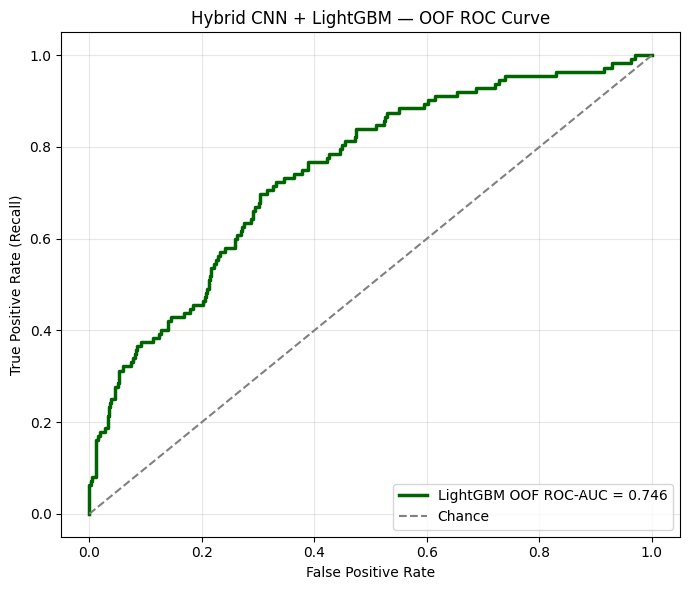


[ROC-AUC] 0.7465


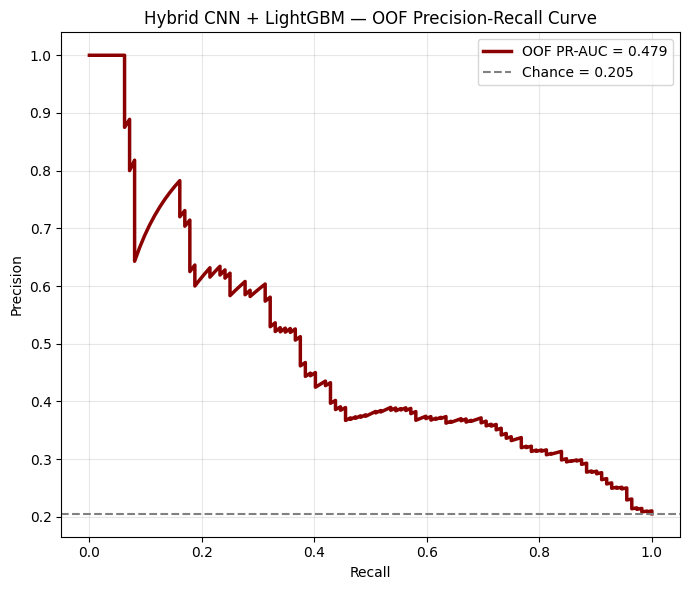

[PR-AUC]  0.4793

OOF PERFORMANCE AT SELECTED THRESHOLD
ROC-AUC     : 0.7465
PR-AUC      : 0.4793
F1          : 0.4108
Recall      : 0.3393
Precision   : 0.5205
Specificity : 0.9194


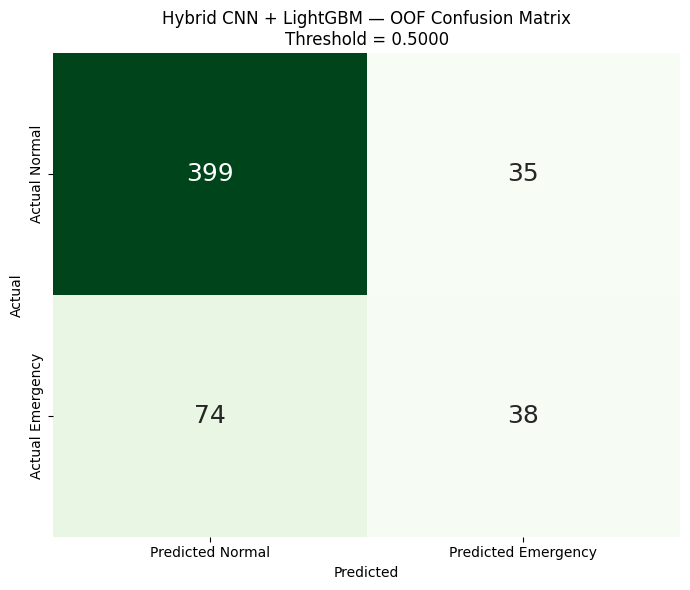


CONFUSION MATRIX COUNTS
True Negatives  (TN): 399
False Positives (FP): 35
False Negatives (FN): 74
True Positives  (TP): 38

FINAL OOF SUMMARY
Patients        : 546
Predictors      : 309
ROC-AUC         : 0.7465
PR-AUC          : 0.4793
Threshold       : 0.500000
Recall          : 0.3393
Precision       : 0.5205
Specificity     : 0.9194
F1              : 0.4108

[OK] OOF evaluation complete.


In [ ]:
# ==============================================================================
# STEP 7 — OOF EVALUATION: ROC-AUC + PR-AUC + CONFUSION MATRIX
# ==============================================================================

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix,
    f1_score,
    recall_score,
    precision_score,
)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("\n" + "=" * 80)
print("OOF MODEL EVALUATION")
print("=" * 80)

# ------------------------------------------------------------------------------
# 1. Verify OOF predictions
# ------------------------------------------------------------------------------

if len(y_probs) != len(y_class):
    raise ValueError(
        f"OOF prediction length mismatch: "
        f"y_probs={len(y_probs)}, y_class={len(y_class)}"
    )

if np.isnan(y_probs).any():
    raise ValueError("NaN values found in OOF predictions.")

print(f"[OK] OOF predictions: {len(y_probs)}")

# ==============================================================================
# 2. ROC-AUC CURVE
# ==============================================================================

fpr, tpr, roc_thresholds = roc_curve(
    y_class,
    y_probs
)

roc_auc = roc_auc_score(
    y_class,
    y_probs
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    color="darkgreen",
    linewidth=2.5,
    label=f"LightGBM OOF ROC-AUC = {roc_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1.5,
    label="Chance"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Hybrid CNN + LightGBM — OOF ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n[ROC-AUC] {roc_auc:.4f}")

# ==============================================================================
# 3. PRECISION-RECALL CURVE
# ==============================================================================

precision_curve, recall_curve, pr_thresholds = (
    precision_recall_curve(
        y_class,
        y_probs
    )
)

pr_auc = average_precision_score(
    y_class,
    y_probs
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall_curve,
    precision_curve,
    color="darkred",
    linewidth=2.5,
    label=f"OOF PR-AUC = {pr_auc:.3f}"
)

# Positive-class prevalence = random baseline
baseline = y_class.mean()

plt.axhline(
    baseline,
    linestyle="--",
    color="gray",
    linewidth=1.5,
    label=f"Chance = {baseline:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Hybrid CNN + LightGBM — OOF Precision-Recall Curve")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"[PR-AUC]  {pr_auc:.4f}")


# ------------------------------------------------------------------------------
# Define threshold (Choose Option A or Option B)
# ------------------------------------------------------------------------------

# Option A: Use a fixed standard threshold
threshold = 0.5

# Option B: Or find the optimal threshold automatically using ROC curve data
# j_scores = tpr - fpr
# best_idx = np.argmax(j_scores)
# threshold = roc_thresholds[best_idx]


# ------------------------------------------------------------------------------
# Define specificity calculation helper
# ------------------------------------------------------------------------------
def specificity_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return tn / (tn + fp) if (tn + fp) > 0 else 0.0


# ==============================================================================
# 5. THRESHOLDED OOF PREDICTIONS
# ==============================================================================

y_pred_sensitive = (
    y_probs >= threshold
).astype(int)

# ==============================================================================
# 6. PERFORMANCE AT SELECTED THRESHOLD
# ==============================================================================

recall_value = recall_score(
    y_class,
    y_pred_sensitive,
    zero_division=0
)

precision_value = precision_score(
    y_class,
    y_pred_sensitive,
    zero_division=0
)

f1_value = f1_score(
    y_class,
    y_pred_sensitive,
    zero_division=0
)

specificity_value = specificity_score(
    y_class,
    y_pred_sensitive
)

print("\n" + "=" * 80)
print("OOF PERFORMANCE AT SELECTED THRESHOLD")
print("=" * 80)

print(f"ROC-AUC     : {roc_auc:.4f}")
print(f"PR-AUC      : {pr_auc:.4f}")
print(f"F1          : {f1_value:.4f}")
print(f"Recall      : {recall_value:.4f}")
print(f"Precision   : {precision_value:.4f}")
print(f"Specificity : {specificity_value:.4f}")

# ==============================================================================
# 7. CONFUSION MATRIX
# ==============================================================================

cm = confusion_matrix(
    y_class,
    y_pred_sensitive,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    cbar=False,
    xticklabels=["Predicted Normal", "Predicted Emergency"],
    yticklabels=["Actual Normal", "Actual Emergency"],
    annot_kws={"size": 18}
)

plt.title(
    "Hybrid CNN + LightGBM — OOF Confusion Matrix\n"
    f"Threshold = {threshold:.4f}"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

# ==============================================================================
# 8. CONFUSION MATRIX COUNTS
# ==============================================================================

print("\n" + "=" * 80)
print("CONFUSION MATRIX COUNTS")
print("=" * 80)

print(f"True Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")

# ==============================================================================
# 9. FINAL SUMMARY
# ==============================================================================

print("\n" + "=" * 80)
print("FINAL OOF SUMMARY")
print("=" * 80)

print(f"Patients        : {len(y_class)}")
print(f"Predictors      : {X.shape[1]}")
print(f"ROC-AUC         : {roc_auc:.4f}")
print(f"PR-AUC          : {pr_auc:.4f}")
print(f"Threshold       : {threshold:.6f}")
print(f"Recall          : {recall_value:.4f}")
print(f"Precision       : {precision_value:.4f}")
print(f"Specificity     : {specificity_value:.4f}")
print(f"F1              : {f1_value:.4f}")

print("\n[OK] OOF evaluation complete.")

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import precision_recall_curve, confusion_matrix

# 1. Safety check to ensure variables are loaded in memory
if 'y_class' not in globals() or 'y_probs' not in globals():
    raise ValueError("Error: 'y_class' or 'y_probs' are missing. Please run your model training block first!")

# Define target sensitivity (recall) levels you want to inspect
target_sensitivities = [0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.60, 0.50]

# Calculate precision, recall, and thresholds from the OOF probabilities
precisions, recalls, thresholds = precision_recall_curve(y_class, y_probs)

results_list = []

for target_sens in target_sensitivities:
    # Find the index where recall is closest to the target sensitivity
    idx = np.argmin(np.abs(recalls - target_sens))

    # Safely map index to thresholds array (avoiding out-of-bounds errors)
    if idx >= len(thresholds):
        t = thresholds[-1] if len(thresholds) > 0 else 0.5
    else:
        t = thresholds[idx]

    # Calculate predictions at this specific threshold
    y_pred_t = (y_probs >= t).astype(int)

    cm = confusion_matrix(y_class, y_pred_t, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    actual_sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    f1 = 2 * (precision * actual_sens) / (precision + actual_sens) if (precision + actual_sens) > 0 else 0

    results_list.append({
        "Target Sensitivity": target_sens,
        "Actual Sensitivity": f"{actual_sens:.3f}",
        "Threshold": f"{t:.4f}",
        "Specificity": f"{specificity:.3f}",
        "Precision": f"{precision:.3f}",
        "F1-Score": f"{f1:.3f}"
    })

df_threshold_table = pd.DataFrame(results_list)

print("\n" + "=" * 80)
print("CLINICAL OPERATING POINTS (SENSITIVITY TARGETS)")
print("=" * 80)
print(df_threshold_table.to_string(index=False))
print("=" * 80)


CLINICAL OPERATING POINTS (SENSITIVITY TARGETS)
 Target Sensitivity Actual Sensitivity Threshold Specificity Precision F1-Score
               0.95              0.946    0.0001       0.260     0.248    0.393
               0.90              0.902    0.0006       0.385     0.274    0.421
               0.85              0.848    0.0016       0.477     0.295    0.438
               0.80              0.804    0.0041       0.546     0.314    0.451
               0.75              0.750    0.0086       0.611     0.332    0.460
               0.70              0.696    0.0196       0.684     0.363    0.477
               0.60              0.598    0.0360       0.737     0.370    0.457
               0.50              0.500    0.0898       0.788     0.378    0.431



STEP 6 — HYBRID CNN + LIGHTGBM (LEAKAGE-SAFE)


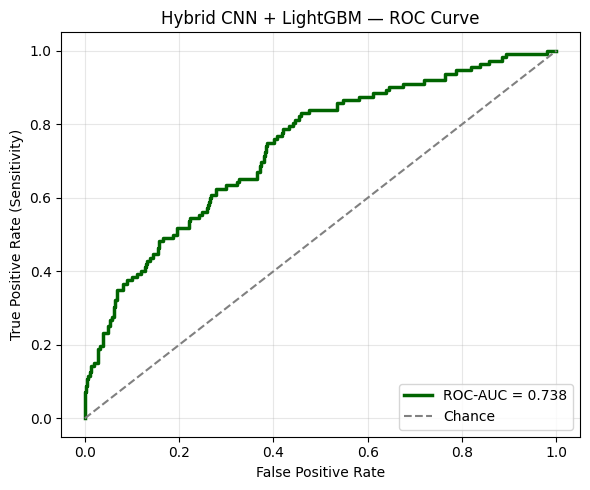


CLINICAL OPERATING POINTS TABLE
 Target Sensitivity Actual Sensitivity Threshold Specificity Precision
               0.95              0.946    0.0000       0.182     0.230
               0.90              0.902    0.0000       0.325     0.256
               0.85              0.848    0.0002       0.465     0.291
               0.80              0.804    0.0006       0.555     0.318
               0.75              0.750    0.0012       0.599     0.326
               0.70              0.696    0.0019       0.620     0.321
               0.60              0.598    0.0096       0.733     0.366
               0.50              0.500    0.0280       0.804     0.397

TOP HYBRID FEATURE IMPORTANCES
                           feature  importance
                fhr_std_escalation       241.4
                           fhr_std       200.0
                           fhr_iqr       197.0
                fhr_std_last_15min       189.6
                        cnn_mean_6       178.2
              

In [ ]:
# ==============================================================================
# STEP 6 — HYBRID CNN + LIGHTGBM (LEAKAGE-SAFE & CLINICAL OPERATING POINTS)
# ==============================================================================

print("\n" + "=" * 80)
print("STEP 6 — HYBRID CNN + LIGHTGBM (LEAKAGE-SAFE)")
print("=" * 80)

import lightgbm as lgb
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    recall_score,
    precision_score,
)
from sklearn.model_selection import StratifiedKFold

# ------------------------------------------------------------------------------
# 1. Helper Functions
# ------------------------------------------------------------------------------

def feature_importance_classifier(models, top_n=30, importance_type="gain"):
    importances = []
    for model in models:
        importances.append(model.feature_importances_)
    mean_importance = np.mean(importances, axis=0)

    try:
        feature_names = X.columns
    except:
        feature_names = [f"feat_{i}" for i in range(len(mean_importance))]

    df_imp = pd.DataFrame({
        "feature": feature_names,
        "importance": mean_importance
    }).sort_values(by="importance", ascending=False)

    return df_imp.head(top_n)

def export_predictions_to_csv(df, y_true, y_probs, y_pred, filename):
    df_out = df.copy()
    df_out["y_true"] = y_true.values if hasattr(y_true, "values") else y_true
    df_out["y_prob"] = y_probs
    df_out["y_pred"] = y_pred
    df_out.to_csv(filename, index=False)
    print(f"[EXPORT] Predictions saved to {filename}")

# ------------------------------------------------------------------------------
# 2. Run Leakage-Safe Training
# ------------------------------------------------------------------------------

robust_params = {
    "num_leaves": 15,
    "max_depth": 5,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_samples": 20,
    "n_estimators": 1000,
    "verbosity": -1,
    "random_state": 42
}

def train_lgbm_grid_tuned(X, y, best_params, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    y_probs = np.zeros(len(X))
    models = []

    for train_idx, val_idx in skf.split(X, y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        model = lgb.LGBMClassifier(**best_params)
        model.fit(X_train, y_train)

        y_probs[val_idx] = model.predict_proba(X_val)[:, 1]
        models.append(model)

    return models, y_probs

models, y_probs = train_lgbm_grid_tuned(X, y_class, best_params=robust_params, n_splits=5)

roc_auc = roc_auc_score(y_class, y_probs)
pr_auc = average_precision_score(y_class, y_probs)

# ------------------------------------------------------------------------------
# 3. Plot ROC Curve
# ------------------------------------------------------------------------------

fpr, tpr, _ = roc_curve(y_class, y_probs)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="darkgreen", linewidth=2.5, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("Hybrid CNN + LightGBM — ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 4. Clinical Operating Points Table (Sensitivity Targets)
# ------------------------------------------------------------------------------

target_sensitivities = [0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.60, 0.50]
precisions_c, recalls_c, thresholds_c = precision_recall_curve(y_class, y_probs)

table_results = []
for target_s in target_sensitivities:
    idx = np.argmin(np.abs(recalls_c - target_s))
    t_opt = thresholds_c[idx] if idx < len(thresholds_c) else 0.5
    y_pred_t = (y_probs >= t_opt).astype(int)

    cm_t = confusion_matrix(y_class, y_pred_t, labels=[0, 1])
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel()

    act_sens = tp_t / (tp_t + fn_t) if (tp_t + fn_t) > 0 else 0
    act_spec = tn_t / (tn_t + fp_t) if (tn_t + fp_t) > 0 else 0
    act_prec = tp_t / (tp_t + fp_t) if (tp_t + fp_t) > 0 else 0

    table_results.append({
        "Target Sensitivity": target_s,
        "Actual Sensitivity": f"{act_sens:.3f}",
        "Threshold": f"{t_opt:.4f}",
        "Specificity": f"{act_spec:.3f}",
        "Precision": f"{act_prec:.3f}"
    })

print("\n" + "=" * 80)
print("CLINICAL OPERATING POINTS TABLE")
print("=" * 80)
print(pd.DataFrame(table_results).to_string(index=False))
print("=" * 80)

# ------------------------------------------------------------------------------
# 5. Feature Importance
# ------------------------------------------------------------------------------

print("\n" + "=" * 80)
print("TOP HYBRID FEATURE IMPORTANCES")
print("=" * 80)
imp = feature_importance_classifier(models, top_n=30, importance_type="gain")
print(imp.to_string(index=False))

print("\n[COMPLETE] Leakage-safe training, ROC curve, and clinical tables finalized.")


PERFORMANCE AT 90% TARGET RECALL (Threshold = 0.0000)
ROC-AUC     : 0.7382
PR-AUC      : 0.4766
Sensitivity : 0.9018 (Target: ~0.90)
Specificity : 0.3249
Precision   : 0.2563
F1-Score    : 0.3992
--------------------------------------------------------------------------------
Confusion Matrix Counts:
  TN: 141 | FP: 293
  FN: 11 | TP: 101


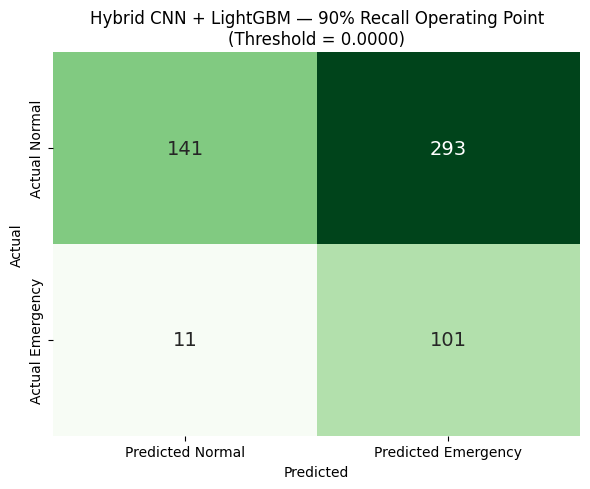

In [ ]:
# ==============================================================================
# EVALUATION & PLOTTING AT 90% RECALL (SENSITIVITY) THRESHOLD
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    precision_recall_curve,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    f1_score,
    recall_score,
    precision_score
)

# 1. Find the threshold that yields ~90% recall (sensitivity)
precisions, recalls, thresholds = precision_recall_curve(y_class, y_probs)

target_recall = 0.90
# Find the index where recall is closest to 0.90
idx_90 = np.argmin(np.abs(recalls - target_recall))
threshold_90 = thresholds[idx_90] if idx_90 < len(thresholds) else 0.5

# 2. Generate predictions using the 90% recall threshold
y_pred_90 = (y_probs >= threshold_90).astype(int)

# 3. Calculate metrics at this threshold
cm_90 = confusion_matrix(y_class, y_pred_90, labels=[0, 1])
tn, fp, fn, tp = cm_90.ravel()

actual_sens = tp / (tp + fn) if (tp + fn) > 0 else 0
actual_spec = tn / (tn + fp) if (tn + fp) > 0 else 0
actual_prec = tp / (tp + fp) if (tp + fp) > 0 else 0
actual_f1 = f1_score(y_class, y_pred_90, zero_division=0)
roc_auc = roc_auc_score(y_class, y_probs)
pr_auc = average_precision_score(y_class, y_probs)

print("\n" + "=" * 80)
print(f"PERFORMANCE AT 90% TARGET RECALL (Threshold = {threshold_90:.4f})")
print("=" * 80)
print(f"ROC-AUC     : {roc_auc:.4f}")
print(f"PR-AUC      : {pr_auc:.4f}")
print(f"Sensitivity : {actual_sens:.4f} (Target: ~0.90)")
print(f"Specificity : {actual_spec:.4f}")
print(f"Precision   : {actual_prec:.4f}")
print(f"F1-Score    : {actual_f1:.4f}")
print("-" * 80)
print(f"Confusion Matrix Counts:\n  TN: {tn} | FP: {fp}\n  FN: {fn} | TP: {tp}")

# 4. Plot Confusion Matrix for 90% Recall Threshold
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_90,
    annot=True,
    fmt="d",
    cmap="Greens",
    cbar=False,
    xticklabels=["Predicted Normal", "Predicted Emergency"],
    yticklabels=["Actual Normal", "Actual Emergency"],
    annot_kws={"size": 14}
)
plt.title(f"Hybrid CNN + LightGBM — 90% Recall Operating Point\n(Threshold = {threshold_90:.4f})")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()